# TP 1

#### Exercice 1

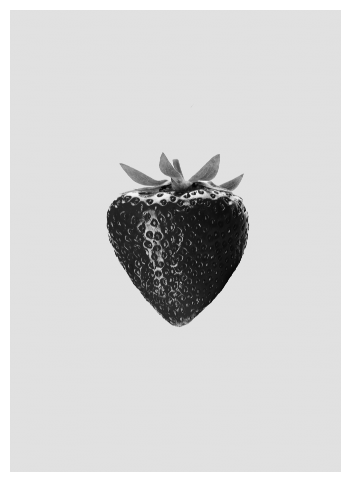

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
myImg = 'allec-gomes-xnRg3xDcNnE-unsplash.jpg'

def to_grayscale(img_bgr: np.ndarray) -> np.ndarray:

    # Vérifier que l’image est bien en 3 canaux
    if len(img_bgr.shape) != 3 or img_bgr.shape[2] != 3:
        raise ValueError("L'image doit être en BGR avec 3 canaux.")

    B = img_bgr[:, :, 0].astype(float)
    G = img_bgr[:, :, 1].astype(float)
    R = img_bgr[:, :, 2].astype(float)

    # Formule de conversion
    gray = 0.299 * R + 0.587 * G + 0.114 * B

    # Normalisation 
    gray = np.clip(gray, 0, 255)        
    gray = gray.astype(np.uint8)

    return gray


img = cv2.imread(myImg)   

gray_img = to_grayscale(img)

# Affichage
plt.figure(figsize=(6,6))
plt.imshow(gray_img, cmap="gray")
plt.axis("off")
plt.show()


### Exercice 2

In [11]:
def seuillage_fixe(img_gray: np.ndarray, T: int) -> np.ndarray:
    


    if img_gray.dtype != np.uint8:
        raise ValueError("L'image doit être au format uint8.")
    if T < 0 or T > 255:
        raise ValueError("Le seuil T doit être dans l'intervalle [0..255].")

    binary = (img_gray >= T).astype(np.uint8) * 255

    return binary


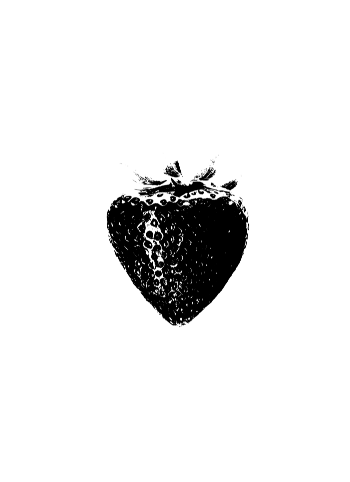

In [12]:
img_gray = cv2.imread(myImg, cv2.IMREAD_GRAYSCALE)

bin_img = seuillage_fixe(img_gray, T=120)

# Affichage
plt.figure(figsize=(6,6))
plt.imshow(bin_img, cmap="gray")
plt.axis("off")
plt.show()


### Exercice 3

In [13]:
def threshold_adaptive_mean(img_gray: np.ndarray, block_size: int, C: int = 0) -> np.ndarray:

    # Vérifications
    if img_gray.dtype != np.uint8:
        raise ValueError("L'image doit être au format uint8.")
    if block_size < 3 or block_size % 2 == 0:
        raise ValueError("block_size doit être un entier impair ≥ 3.")

    # Calcul de la moyenne locale
    mean_local = cv2.blur(img_gray.astype(np.float32), (block_size, block_size))

    # Calcul du seuil local T(x,y)
    T = mean_local - C

    # Application du seuillage
    binary = (img_gray > T).astype(np.uint8) * 255

    return binary


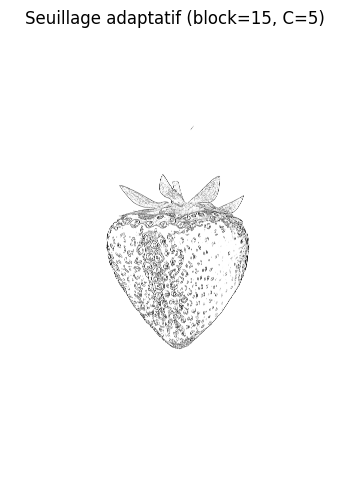

In [14]:
img_gray = cv2.imread(myImg, cv2.IMREAD_GRAYSCALE)

bin_img = threshold_adaptive_mean(img_gray, block_size=15, C=5)

plt.figure(figsize=(6,6))
plt.imshow(bin_img, cmap="gray")
plt.title("Seuillage adaptatif (block=15, C=5)")
plt.axis("off")
plt.show()


### Exercice 4

In [18]:
import numpy as np

def threshold_otsu(img_gray: np.ndarray) -> tuple[np.ndarray, int]:

    if img_gray.dtype != np.uint8:
        raise ValueError("L'image doit être uint8.")

    hist, _ = np.histogram(img_gray, bins=256, range=(0, 256))
    total_pixels = img_gray.size

    prob = hist / total_pixels

    omega = np.cumsum(prob)               
    mu = np.cumsum(prob * np.arange(256)) 

    
    mu_total = mu[-1]

    
    sigma_b_squared = (mu_total * omega - mu)**2 / (omega * (1 - omega))

    
    sigma_b_squared = np.nan_to_num(sigma_b_squared)

    # Trouver le T optimal
    T = np.argmax(sigma_b_squared)

    # Appliquer le seuil
    binary = (img_gray >= T).astype(np.uint8) * 255

    return binary, T


C:\Users\ATRARI\AppData\Local\Temp\ipykernel_13492\2638119728.py:20: RuntimeWarning: invalid value encountered in divide
  sigma_b_squared = (mu_total * omega - mu)**2 / (omega * (1 - omega))


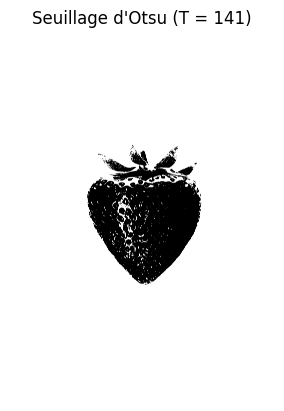

In [16]:
img_gray = cv2.imread(myImg, cv2.IMREAD_GRAYSCALE)

binary_img, T = threshold_otsu(img_gray)

plt.imshow(binary_img, cmap="gray")
plt.title(f"Seuillage d'Otsu (T = {T})")
plt.axis("off")
plt.show()


In [8]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

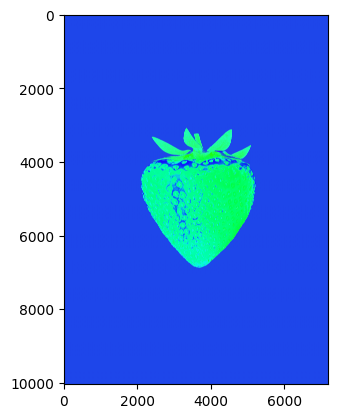

In [10]:
img_bgr = cv2.imread('fraise.jpg')
img_hsv = cv2.cvtColor(img_bgr , cv2.COLOR_BGR2HSV)

plt.imshow(img_hsv)


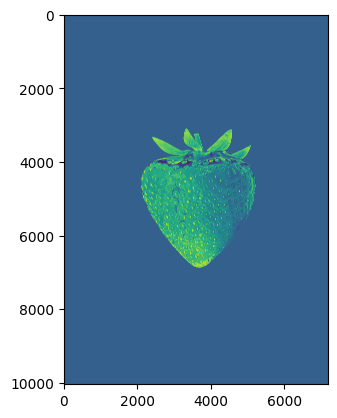

In [16]:
h, s, v = cv2.split(img_hsv)


plt.imshow(h+v)
